# Google Hackathon · Step 3 Simulator + Step 4 Profit Maximization
### DADS5250 · Generative AI & LangChain · Beer Game-style staffing decisions

**Inputs:** Upload just **two separate CSV files** to Colab: `countries.csv` and `forecast_2026.csv` (duplicate-download names such as `countries(2).csv` are automatically normalized). No ZIP and no embedded data.

**Decision methods:**
1. **Manual / hold / rule-based** staffing simulations.
2. **Profit optimizer** that searches all 12 months at once, using integer hiring, releases, salaries, hire delays, advertiser onboarding and modeled recurring revenue. It can optimize purely for profit or subject to a **minimum service rate**.
3. **Full GenAI / GenAI-Assisted**: LangChain's ChatOpenAI decides each month from the latest observed state. Optionally, GenAI may see the optimizer's recommended action as advice (a **hybrid**, which must be labeled separately).

**Fair comparison:** The Python financial simulation calculates the results for *all* approaches. The optimizer has perfect foresight of the **2026 forecast**, while the live AI sees only its present and next-month forecast; thus comparisons are illustrative, not proof of model superiority. The opt-in live API path requires an OpenAI API key and incurs model API charges.


In [1]:
%pip install -q langchain-core langchain-openai

In [2]:
from google.colab import files

uploaded = files.upload()

Saving forecast_2026.csv to forecast_2026.csv
Saving countries.csv to countries.csv


In [3]:
# Google Colab: upload the two input datasets (CSV files stay separate).
# Your computer may show names such as countries(2).csv and forecast_2026(2).csv.
# This cell standardizes them INSIDE Colab to countries.csv and forecast_2026.csv.
from pathlib import Path
import re
import shutil

DATA_FOLDER = Path('/content') if Path('/content').is_dir() else Path.cwd()
REQUIRED_CSVS = ('countries.csv', 'forecast_2026.csv')

def standard_name(filename):
    """Discard only the duplicate-download suffix, e.g. countries(2).csv -> countries.csv."""
    m = re.fullmatch(r'(countries|forecast_2026)\s*(?:\(\d+\))?\.csv',
                     Path(filename).name, flags=re.IGNORECASE)
    return f'{m.group(1).lower()}.csv' if m else None

def normalize_uploads(directory=DATA_FOLDER):
    """Use the selected CSVs without modifying files on the user's computer."""
    for canonical in REQUIRED_CSVS:
        target = directory / canonical
        if target.is_file():
            continue
        candidates = [f for f in directory.glob('*.csv')
                      if standard_name(f.name) == canonical]
        if not candidates:
            continue
        # If several duplicate-download versions exist, use the newest uploaded version.
        source = max(candidates, key=lambda p: p.stat().st_mtime_ns)
        shutil.copyfile(source, target)
        print(f'Using {source.name} as {canonical}')

normalize_uploads()
missing = [name for name in REQUIRED_CSVS if not (DATA_FOLDER / name).is_file()]
if missing:
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(f'Place the required files in {DATA_FOLDER}: {missing}')
    print('Select TWO files: one countries CSV and one forecast_2026 CSV.')
    uploaded = files.upload()
    selected = [standard_name(name) for name in uploaded]
    selected = [name for name in selected if name in REQUIRED_CSVS]
    if len(selected) != len(set(selected)):
        raise ValueError('More than one copy of the same dataset selected. Upload one countries file and one forecast file.')
    # Colab stores uploaded files in the current working directory.
    for original, content in uploaded.items():
        canonical = standard_name(original)
        if canonical is not None:
            (DATA_FOLDER / canonical).write_bytes(content)
    normalize_uploads()

missing = [name for name in REQUIRED_CSVS if not (DATA_FOLDER / name).is_file()]
if missing:
    raise FileNotFoundError(f'Missing required CSV(s): {missing}. Re-run this cell and upload the missing file(s).')
print('Ready! Step 3 uses exactly these two data files:')
for name in REQUIRED_CSVS:
    print(' -', DATA_FOLDER / name)


Ready! Step 3 uses exactly these two data files:
 - /content/countries.csv
 - /content/forecast_2026.csv


In [4]:
from pathlib import Path
from dataclasses import dataclass
from collections import deque
import os, json, math, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PATHS = [Path('.'), Path('data/clean'), Path('/content'), Path('/mnt/data')]
def locate(filename):
    for folder in PATHS:
        path = folder / filename
        if path.is_file():
            return path
    raise FileNotFoundError(f"Could not find {filename}. Run the Colab upload cell above.")

countries = pd.read_csv(locate('countries.csv'))
forecast = pd.read_csv(locate('forecast_2026.csv'))
required_a = {'Country','Existing_Agent_Count','Annual_Agent_Salary_USD'}
required_b = {'Country','Month','Forecast_Eligible_Signups','Avg_Budget'}
assert required_a.issubset(countries), required_a-set(countries)
assert required_b.issubset(forecast), required_b-set(forecast)
assert not countries.Country.duplicated().any()
assert not forecast[['Country','Month']].duplicated().any()
assert set(forecast.Country)==set(countries.Country)
assert len(forecast)==len(countries)*12
assert (forecast.groupby('Country').Month.nunique()==12).all()
assert (forecast[['Forecast_Eligible_Signups','Avg_Budget']]>=0).all().all()
assert (countries[['Existing_Agent_Count','Annual_Agent_Salary_USD']]>=0).all().all()
inputs = forecast.merge(countries[['Country','Existing_Agent_Count','Annual_Agent_Salary_USD']], on='Country',validate='many_to_one').sort_values(['Country','Month'])
print(f'Loaded {len(countries)} countries, {len(inputs)} country-month records, {inputs.Forecast_Eligible_Signups.sum():,.0f} expected eligible sign-ups.')
display(inputs.head())

Loaded 22 countries, 264 country-month records, 106,167 expected eligible sign-ups.


,Country,Month,Forecast_Eligible_Signups,Avg_Budget,Existing_Agent_Count,Annual_Agent_Salary_USD
0,Argentina,1,70.8,11131.83,200,18687
1,Argentina,2,68.2,11131.83,200,18687
2,Argentina,3,69.1,11131.83,200,18687
3,Argentina,4,68.7,11131.83,200,18687
4,Argentina,5,68.3,11131.83,200,18687


## 1 · Business rules and assumptions


*Assumed revenue proxy:* each advertiser that completes onboarding contributes `Avg_Budget × capture_rate / 12` for each month remaining in 2026. Advertiser **budget is not Google's revenue**; `capture_rate` is a hypothetical take-rate used only for demonstration. Existing staffing cost is shown on an allocated basis (20% of existing team time).

**Revised modeling note:** An advertiser served in a particular month retains the revenue contribution associated with its original forecast cohort; we do not apply a later month's average budget to every previously served advertiser. Advertiser churn and true take rates remain unknown.


**Optimization objective:** maximize the sum of modeled 2026 monthly revenue minus allocated salaries and hiring costs. An unconstrained optimizer may choose to leave customers waiting if serving them would cost more than the estimated revenue; an optional **minimum annual service rate** provides an explicit service-quality constraint. Revenue is credited only after sign-ups are actually served; cohort budgets do not change after onboarding. The model uses 2026 recurring revenue only—future years, severance, training, and customer lifetime value are out of scope.


In [5]:
@dataclass(frozen=True)
class GameRules:
    cases_per_agent_month: float = 10.0   # illustration only
    existing_time_share: float = 0.20      # fraction existing agents can use for onboarding
    hire_lead_months: int = 1             # start next month after an order
    max_wait_months: int = 2              # FIFO waiting limit; abandon at start of later month
    hire_fee_fraction: float = 0.08       # one-off 8% annual salary / hire at activation
    revenue_capture_rate: float = 0.10    # not a verified Google take rate
    max_hires_per_month: int = 150        # format/absolute safety guardrail
    capacity_buffer: float = 0.10        # assumed demand cushion (illustrative, 10%)
RULES = GameRules()

# Example run: one country = 12 decision rounds / 12 LLM calls; change to any name in countries.Country.
DEMO_COUNTRY = 'USA'
assert DEMO_COUNTRY in set(countries.Country)
print('Rules:', RULES)
print('Available countries:', ', '.join(countries.Country.tolist()))

Rules: GameRules(cases_per_agent_month=10.0, existing_time_share=0.2, hire_lead_months=1, max_wait_months=2, hire_fee_fraction=0.08, revenue_capture_rate=0.1, max_hires_per_month=150, capacity_buffer=0.1)
Available countries: USA, UK, Germany, India, Brazil, Japan, Australia, Canada, France, Mexico, China, Italy, Spain, Poland, South Korea, South Africa, Vietnam, Argentina, Turkey, Indonesia, Thailand, UAE


## 2 · Decision contract: what can GenAI control?

Exactly like the Beer Game's order quantity, the LLM controls **how many flexible staff to order (`hire`) and how many *active flexible* staff to release (`release`) in the current month**. It cannot change the forecast, annual salary, backlog, service capacity, or financial formulas.

**No looking ahead:** The prompt includes the current month's *forecast*, past observed arrivals, hiring pipeline, and backlog, **not** current-month realized arrivals, which are revealed *after* the decision. The same 2026 demand is used for every decision approach.

**Safety:** Numeric validation rejects negative/noninteger decisions and other malformed actions. A separate **economic capacity guardrail** caps requested hires at a forecast-supported shortfall, prevents releasing capacity needed for predicted demand, and prevents hires that arrive after 2026. Raw suggestions are saved alongside applied decisions. Invalid model replies become a clearly logged **no-change fallback**, not a fabricated valid LLM decision.

In [6]:
def check_action(proposed, observed, rules=RULES):
    if not isinstance(proposed, dict): raise ValueError('Decision must be a JSON object')
    hire, release = proposed.get('hire'), proposed.get('release')
    if type(hire) is not int or type(release) is not int: raise ValueError('hire and release must be integers')
    if min(hire,release)<0: raise ValueError('No negative actions')
    if hire>rules.max_hires_per_month: raise ValueError('Hires exceed safe maximum')
    if release>observed['active_flexible_agents']: raise ValueError('Releases exceed active flexible staff')
    if hire and release: raise ValueError('Cannot hire and release in same month')
    return {'hire':hire,'release':release,'reason':str(proposed.get('reason',''))[:1500]}

def augment_capacity_state(observed, rules=RULES):
    """Show the LLM mathematically derived capacity and financially relevant limits.

    Uses known forecasts, not realized future demand. The 10% buffer is an
    explicitly stated scenario assumption, NOT a Google policy.
    """
    state = dict(observed)
    current_agents = float(state['existing_agents'])*rules.existing_time_share + int(state['active_flexible_agents'])
    pending_next = int(state['pending_hires'].get(str(state['month']+1), 0))
    capacity_now = current_agents * rules.cases_per_agent_month
    capacity_next_before_new = (current_agents + pending_next) * rules.cases_per_agent_month
    forecast_next = state.get('forecast_next_month')
    backlog = int(state['backlog_start'])
    target_today = (float(state['forecast_this_month']) + backlog)*(1+rules.capacity_buffer)
    target_next = ((float(forecast_next) + backlog)*(1+rules.capacity_buffer)
                   if forecast_next is not None else 0.0)
    hires_shortfall = max(0, math.ceil((target_next-capacity_next_before_new)/rules.cases_per_agent_month-1e-9))
    if state['month'] + rules.hire_lead_months > 12:
        hires_shortfall = 0
    # Releasing active staff must not create a shortfall this month or next month.
    required_today_flex = max(0, math.ceil((target_today/rules.cases_per_agent_month)
                                       - float(state['existing_agents'])*rules.existing_time_share - 1e-9))
    required_next_flex = max(0, math.ceil((target_next/rules.cases_per_agent_month)
                                      - float(state['existing_agents'])*rules.existing_time_share - pending_next - 1e-9))
    max_safe_release = max(0, int(state['active_flexible_agents'])-max(required_today_flex,required_next_flex))
    state.update({
        'current_capacity_cases': int(math.floor(capacity_now)),
        'projected_next_month_capacity_before_new_hires': int(math.floor(capacity_next_before_new)),
        'next_month_target_with_buffer': round(target_next, 2) if forecast_next is not None else None,
        'max_justified_hires': min(rules.max_hires_per_month,int(hires_shortfall)),
        'max_safe_releases': int(max_safe_release),
        'capacity_buffer_fraction':rules.capacity_buffer,
        'financial_rule':'Each hired active agent costs salary / 12 monthly, plus a one-time hiring fee at activation.',
    })
    return state


def capacity_guardrail(action, state):
    """Return the applied action and a transparent explanation of any adjustment.

    A model suggestion remains a model suggestion; any clipped action is clearly
    marked as a safeguard adjustment, not falsely credited as the raw LLM choice.
    """
    applied = dict(action)
    notes = []
    if applied['hire'] > state['max_justified_hires']:
        notes.append(f"hire {applied['hire']} -> {state['max_justified_hires']} (no supported capacity shortfall)")
        applied['hire'] = int(state['max_justified_hires'])
    if applied['release'] > state['max_safe_releases']:
        notes.append(f"release {applied['release']} -> {state['max_safe_releases']} (protect service capacity)")
        applied['release'] = int(state['max_safe_releases'])
    note='; '.join(notes)
    if note:
        applied['reason'] = f"[CAPACITY GUARDRAIL: {note}] Model reason: " + str(applied.get('reason',''))
    return applied, note

# Manual plans are simply explicit monthly actions, analogous to the Beer Game's Manual mode.
MANUAL_ACTIONS = {1: {'hire': 10, 'release': 0, 'reason': 'User example: hire in January'},
                  8: {'hire': 0, 'release': 5, 'reason': 'User example: release in August'}}
def manual_decider(observed):
    return MANUAL_ACTIONS.get(observed['month'], {'hire':0, 'release':0, 'reason':'No change'})

def no_change_decider(observed):
    return {'hire':0, 'release':0, 'reason':'Keep current team'}

def average_decider(observed):
    # Simple Beer Game-style baseline using current forecast and backlog (NOT optimization).
    rules = RULES
    needed = math.ceil((observed['forecast_this_month'] + observed['backlog_start']) / rules.cases_per_agent_month)
    existing_equiv = observed['existing_agents']*rules.existing_time_share
    desired = max(0,needed - math.floor(existing_equiv))
    active = observed['active_flexible_agents']
    pipeline = sum(observed['pending_hires'].values())
    hire = max(0,min(rules.max_hires_per_month, desired-active-pipeline))
    if observed['month'] + rules.hire_lead_months > 12: hire = 0
    release = max(0,active-desired) if not hire else 0
    return {'hire': int(hire), 'release': int(release), 'reason':'Transparent demand/backlog rule'}

# Validate a sample to demonstrate numeric guardrails.
try:
    check_action({'hire':9999, 'release':0}, {'month':1, 'active_flexible_agents':0})
except ValueError as exc:
    print('Guardrail check:', exc)

Guardrail check: Hires exceed safe maximum


## 3 · The stateful Beer Game simulation engine (**core Step 3**)

Each monthly turn: (1) prior hires arrive; (2) old sign-up requests may abandon; (3) decision maker sees forecast + history and decides; (4) order goes into the lead-time pipeline; (5) actual sign-ups arrive; (6) FIFO service capacity is applied; (7) revenue, staffing cost and profit are recorded. This pattern is deliberately parallel to the Beer Game's ordering/shipping/inventory/holding-cost loop.

**Input to the engine:** `decision_fn(state) -> {'hire': int, 'release': int, 'reason': str}`. That function can be manual, rule-based, or a *real* LLM chain. Each call changes the next month's state.
**Capacity-aware GenAI:** The AI receives `current_capacity_cases`, `projected_next_month_capacity_before_new_hires`, `max_justified_hires`, and `max_safe_releases`. Its raw suggestions are preserved, while operational guardrails cap financially unjustified orders and releases.


In [7]:
def simulate_game(country, decision_fn, label, rules=RULES, enforce_capacity_guardrail=True):
    part = inputs[inputs.Country==country].sort_values('Month').reset_index(drop=True)
    if len(part)!=12: raise ValueError('Country must have 12 rows')
    existing = int(part.Existing_Agent_Count.iloc[0]); salary = float(part.Annual_Agent_Salary_USD.iloc[0])
    active=0; active_advertisers=0; active_monthly_revenue_usd=0.0; pending={}; fifo=deque(); history=[]; rows=[]; audit=[]
    for r in part.itertuples(index=False):
        month=int(r.Month)
        started=pending.pop(month,0)
        active += started
        expired=0
        while fifo and month - fifo[0][0] > rules.max_wait_months:
            expired += fifo.popleft()[1]
        backlog_start=sum(bucket[1] for bucket in fifo)
        # The observable state excludes actual current-month arrivals.
        observed = {
            'country': country, 'month':month,
            'forecast_this_month':round(float(r.Forecast_Eligible_Signups),2),
            'forecast_next_month':round(float(part.loc[month,'Forecast_Eligible_Signups']),2) if month<12 else None,
            'recent_history':history[-3:],
            'backlog_start':backlog_start, 'abandoned_before_decision':expired,
            'existing_agents':existing, 'existing_capacity_share':rules.existing_time_share,
            'cases_per_agent_month':rules.cases_per_agent_month,
            'active_flexible_agents':active,
            'pending_hires':{str(k):int(v) for k,v in pending.items()},
            'hire_lead_months':rules.hire_lead_months,
            'max_hires_per_month':rules.max_hires_per_month,
            'monthly_flexible_agent_salary_usd':round(salary/12,2),
            'one_time_hire_fee_usd':round(salary*rules.hire_fee_fraction,2),
            'model_revenue_capture_rate':rules.revenue_capture_rate,
            'avg_advertiser_budget_usd':round(float(r.Avg_Budget),2),
            'active_advertisers':active_advertisers
        }
        observed=augment_capacity_state(observed,rules)
        source_name = label
        suggested = None
        guardrail_note = ''
        try:
            suggested = decision_fn(observed)
            numeric_checked = check_action(suggested, observed, rules)
            if enforce_capacity_guardrail:
                checked,guardrail_note = capacity_guardrail(numeric_checked,observed)
            else:
                # Used only for validated optimization plans. Heuristic demand buffers
                # must not override a mathematically chosen profit/service trade-off.
                checked,guardrail_note = numeric_checked, ""
            if guardrail_note:
                source_name = label + ' [GUARDRAIL ADJUSTED]'
        except Exception as error:
            checked = {'hire':0,'release':0,'reason':f'Invalid decision / API error: {type(error).__name__}: {str(error)[:100]}'}
            source_name = 'SAFE_FALLBACK_NOT_LLM'
        active -= checked['release']
        if rules.hire_lead_months==0:
            active += checked['hire']; started += checked['hire']
        elif checked['hire']:
            arrive_in = month+rules.hire_lead_months
            pending[arrive_in]=pending.get(arrive_in,0)+checked['hire']

        arrivals = int(math.floor(float(r.Forecast_Eligible_Signups)+0.5))
        if arrivals: fifo.append([month,arrivals,float(r.Avg_Budget)])
        capacity = int(math.floor((existing*rules.existing_time_share + active)*rules.cases_per_agent_month+1e-9))
        served=served_new=0
        capacity_left=capacity
        while capacity_left>0 and fifo:
            born,n,budget_per_advertiser=fifo[0]
            fulfilled=min(capacity_left,n)
            served += fulfilled; served_new += fulfilled if born==month else 0
            # Preserve the monthly revenue contribution of this specific served cohort.
            active_monthly_revenue_usd += fulfilled*budget_per_advertiser*rules.revenue_capture_rate/12
            capacity_left -= fulfilled
            if n==fulfilled: fifo.popleft()
            else: fifo[0][1] = n-fulfilled
        backlog_end=sum(bucket[1] for bucket in fifo)
        active_advertisers += served
        revenue_usd=active_monthly_revenue_usd  # cohort-based recurring revenue proxy
        baseline_allocation_usd=existing*rules.existing_time_share*salary/12
        flexible_salary_usd=active*salary/12
        hiring_fee_usd=started*salary*rules.hire_fee_fraction
        staffing_cost_usd=baseline_allocation_usd+flexible_salary_usd+hiring_fee_usd
        profit_usd=revenue_usd-staffing_cost_usd
        entry={
            'Policy':label, 'Country':country,'Month':month,'Forecast':float(r.Forecast_Eligible_Signups),
            'Arrivals':arrivals,'Hires_Ordered':checked['hire'],'Hires_Activated':started,
            'Releases':checked['release'],'Active_Flexible':active,
            'Pending_End':sum(pending.values()),'Existing_Agents':existing,
            'Capacity':capacity,'Served':served,'Served_Same_Month':served_new,
            'Abandoned':expired,'Backlog_Start':backlog_start,'Backlog_End':backlog_end,
            'Active_Advertisers':active_advertisers,'Modeled_Revenue_USD':revenue_usd,
            'Allocated_Existing_Salary_USD':baseline_allocation_usd,
            'Flexible_Salary_USD':flexible_salary_usd,'Hiring_Fee_USD':hiring_fee_usd,
            'Total_Staffing_Cost_USD':staffing_cost_usd,'Modeled_Profit_USD':profit_usd,
            'Action_Source':source_name,'Reason':checked['reason'],
            'Proposed_Hires': suggested.get('hire') if isinstance(suggested,dict) else None,
            'Proposed_Releases': suggested.get('release') if isinstance(suggested,dict) else None,
            'Guardrail_Note':guardrail_note
        }
        rows.append(entry)
        audit.append({'Policy':label,'Country':country,'Month':month,
                      'Observed_State_JSON':json.dumps(observed,sort_keys=True),
                      'Raw_LLM_Or_Policy_Action_JSON':json.dumps(suggested),
                      'Applied_Action_JSON':json.dumps(checked),'Action_Source':source_name,
                      'Guardrail_Note':guardrail_note})
        history.append({'month':month,'actual_arrivals':arrivals,'served':served,
                        'backlog_end':backlog_end,'hires_ordered':checked['hire'],
                        'releases':checked['release'],'modeled_profit_usd':round(profit_usd,2)})
    out=pd.DataFrame(rows)
    assert (out.Arrivals.cumsum() == out.Served.cumsum() + out.Abandoned.cumsum() + out.Backlog_End).all(), 'Sign-up conservation failed'
    assert (out.Served<=out.Capacity).all(), 'Service exceeded capacity'
    assert (out[['Active_Flexible','Backlog_End','Served','Abandoned','Hires_Activated']]>=0).all().all()
    return out,pd.DataFrame(audit)

def summarize_runs(detail):
    if len(detail)==0: return pd.DataFrame()
    a=(detail.groupby('Policy',as_index=False).agg(Arrivals=('Arrivals','sum'),Served=('Served','sum'),
            Abandoned=('Abandoned','sum'),Year_End_Backlog=('Backlog_End','last'),
            Hires_Ordered=('Hires_Ordered','sum'),
            Modeled_Revenue_USD=('Modeled_Revenue_USD','sum'),
            Staffing_Cost_USD=('Total_Staffing_Cost_USD','sum'),
            Modeled_Profit_USD=('Modeled_Profit_USD','sum')))
    a['Service_Rate']=(a.Served/a.Arrivals.replace(0,np.nan))*100
    return a
print('Simulator ready; policy function can be Python or LangChain.')

Simulator ready; policy function can be Python or LangChain.


## 4 · Run reproducible non-AI policies first

These are **control groups**, not GenAI runs. Their purpose is to test the engine and provide a fair comparison once you execute the live LLM. They use the **same** monthly 2026 country demand.

In [8]:
controls = {}
control_audits = {}
for name, policy in {'Manual':manual_decider, 'Average rule':average_decider, 'Keep current staff':no_change_decider}.items():
    controls[name],control_audits[name] = simulate_game(DEMO_COUNTRY,policy,name)
control_results=pd.concat(controls.values(),ignore_index=True)
print('Offline controls — NOT GenAI results:')
display(summarize_runs(control_results).round(2))
print('Sample monthly timeline:')
display(controls['Manual'][['Month','Arrivals','Hires_Ordered','Hires_Activated','Active_Flexible','Served','Backlog_End','Modeled_Revenue_USD','Total_Staffing_Cost_USD','Modeled_Profit_USD']].head(6))

Offline controls — NOT GenAI results:


,Policy,Arrivals,Served,Abandoned,Year_End_Backlog,Hires_Ordered,Modeled_Revenue_USD,Staffing_Cost_USD,Modeled_Profit_USD,Service_Rate
0,Average rule,13057,13057,0,0,36,56350983.47,10701922.63,45649060.84,100.00
1,Keep current staff,13057,12648,0,409,0,55936279.89,10134818.40,45801461.49,96.87
2,Manual,13057,12648,0,409,0,55936279.89,10134818.40,45801461.49,96.87


Sample monthly timeline:


,Month,Arrivals,Hires_Ordered,Hires_Activated,Active_Flexible,Served,Backlog_End,Modeled_Revenue_USD,Total_Staffing_Cost_USD,Modeled_Profit_USD
0,1,1025,0,0,0,1025,0,7.341471e+05,844568.2,-1.104211e+05
1,2,988,0,0,0,988,0,1.441793e+06,844568.2,5.972251e+05
2,3,1001,0,0,0,1001,0,2.158751e+06,844568.2,1.314182e+06
3,4,995,0,0,0,995,0,2.871411e+06,844568.2,2.026842e+06
4,5,989,0,0,0,989,0,3.579773e+06,844568.2,2.735205e+06
5,6,848,0,0,0,848,0,4.187145e+06,844568.2,3.342577e+06


## 5 · Test a simulated **decision callback** (without falsely claiming an API call)

The purpose of this mock is to verify that **a changing decision each month actually modifies the game state**. The callback does *not* run GenAI and its output is **not** part of the live-LLM comparison.

In [9]:
class ScriptedDecisionTest:
    def __init__(self): self.observations=[]
    def __call__(self, state):
        self.observations.append(dict(state))
        if state['month']==9: return {'hire':12,'release':0,'reason':'Mock test: September order for October peak'}
        return {'hire':0,'release':0,'reason':'Mock test: hold'}
mock=ScriptedDecisionTest()
mock_result,mock_audit=simulate_game(DEMO_COUNTRY,mock,'Scripted test (not GenAI)')
assert len(mock.observations)==12
assert mock_result.loc[mock_result.Month==9,'Hires_Ordered'].iloc[0]==12
assert mock_result.loc[mock_result.Month==10,'Hires_Activated'].iloc[0]==12
assert mock.observations[9]['recent_history'][-1]['hires_ordered']==12
print('Passed: September decision -> October hiring activation -> updated decision history.')

Passed: September decision -> October hiring activation -> updated decision history.


### 5b · Regression test: prevent the overhiring seen in the first GenAI run

The first version ordered 148 hires in January even though existing capacity already covered demand. This test deliberately proposes that bad action and verifies that the simulator (a) records the raw suggestion and (b) applies **zero** unsupported January hires. The test is **not** a live LLM call.

In [10]:
def excessively_aggressive_policy(state):
    return {'hire': 148, 'release': 0, 'reason': 'Intentionally bad suggestion: hire 148'}

checked_result, checked_audit = simulate_game(DEMO_COUNTRY, excessively_aggressive_policy, 'Guardrail regression test')
assert checked_result.loc[0, 'Proposed_Hires'] == 148
assert checked_result.loc[0, 'Hires_Ordered'] == 0
assert 'GUARDRAIL' in checked_result.loc[0, 'Action_Source']
assert (checked_result.Hires_Ordered <= RULES.max_hires_per_month).all()
print('PASS: Existing capacity covers January demand; 148 raw proposed hires become 0 applied hires.')
display(checked_result[['Month', 'Forecast', 'Proposed_Hires', 'Hires_Ordered', 'Guardrail_Note']].head(4))

PASS: Existing capacity covers January demand; 148 raw proposed hires become 0 applied hires.


,Month,Forecast,Proposed_Hires,Hires_Ordered,Guardrail_Note
0,1,1025.0,148,0,hire 148 -> 0 (no supported capacity shortfall)
1,2,988.4,148,0,hire 148 -> 0 (no supported capacity shortfall)
2,3,1000.9,148,0,hire 148 -> 0 (no supported capacity shortfall)
3,4,995.1,148,0,hire 148 -> 0 (no supported capacity shortfall)


## 6 · Maximize modeled profit with integer programming

This is **real numerical optimization**, not an LLM claiming to optimize. `scipy.optimize.milp` finds an annual country staffing plan with integer hires/releases and the same monthly activation delay and staffing costs as the simulator.

**Decision variables:** monthly hires, monthly releases, active flexible agents, and the number of eligible advertisers served from each monthly arrival cohort. Cohorts can be served in their arrival month or up to `max_wait_months` later. Objective weights credit earlier onboarding with more months of 2026 modeled revenue.

**Constraints:** hiring order cap, hiring lead time, no simultaneous hire/release, no negative headcount, service capacity, no service before sign-up, no service after maximum wait, and *optionally* at least a specified share of total annual eligible sign-ups served by December.

For your files, the average budget is constant within each country in 2026. That makes the MILP's cohort-level objective compatible with the simulator's oldest-first (FIFO) service accounting. The notebook tests that the optimal plan, replayed in the simulator, satisfies its service requirement and matches the optimization result.

**Two modes:**
- **Unconstrained profit maximization:** no hard service-rate requirement (may sacrifice service for profit).
- **Profit maximization with 98% annual service target:** maximize profit *subject to* serving at least 98% of the year's sign-ups. Change `MIN_ANNUAL_SERVICE_RATE` to try other business standards.

The optimizer uses the full 2026 **forecast** as its known planning horizon; your GenAI decision-maker does not have this foresight. A solver may report a nonzero MIP gap; check `Optimality_Gap` before calling an answer mathematically optimal.

**Default:** the cell first demonstrates both plans for USA, then Section 6b runs both optimizers for all 22 countries.


In [11]:
# This cell is self-contained after Sections 0-3. It does not need an LLM or API key.
# On Colab: %pip install -q "scipy>=1.9" if the import below fails.
from scipy.optimize import milp, Bounds, LinearConstraint
from scipy.sparse import lil_matrix

MIN_ANNUAL_SERVICE_RATE = 0.98  # editable business constraint (not sourced from the data)
OPTIMIZER_TIME_LIMIT_SECONDS = 40
OPTIMIZER_MIP_REL_GAP = 1e-6
OPTIMIZE_ALL_COUNTRIES = True  # Default: optimize all 22 countries; set False for a short USA-only run


def maximize_staffing_profit(country, min_service_rate=None, rules=RULES):
    """Mixed-integer profit-maximization for one country and one 12-month horizon.

    Returns a validated plan and solver metadata. The optimizer's objective is
    exactly the calendar-2026 cohort revenue minus active-flex salaries and
    hiring fees; existing allocated salary is constant across candidate plans.
    """
    if min_service_rate is not None and not 0 <= min_service_rate <= 1:
        raise ValueError('min_service_rate must be between 0 and 1, or None')
    part = inputs.loc[inputs.Country == country].sort_values('Month').reset_index(drop=True)
    if len(part) != 12:
        raise ValueError(f'Expected 12 rows for {country}')
    horizon = len(part)
    salary = float(part.Annual_Agent_Salary_USD.iloc[0])
    annual_budget = part.Avg_Budget.to_numpy(dtype=float)
    if not np.allclose(annual_budget, annual_budget[0], rtol=0, atol=1e-5):
        raise ValueError('This exact FIFO-equivalent optimizer requires a constant budget within each country')
    arrivals = np.floor(part.Forecast_Eligible_Signups.to_numpy(dtype=float) + .5).astype(int)
    existing = int(part.Existing_Agent_Count.iloc[0])
    base_capacity = int(math.floor(existing * rules.existing_time_share * rules.cases_per_agent_month + 1e-9))
    productivity = float(rules.cases_per_agent_month)
    # If fractional productivity is used, integer variable capacity would need
    # additional rounding constraints. The course assumptions use integer 10.
    if not productivity.is_integer():
        raise ValueError('Optimization requires integer cases_per_agent_month in this notebook')
    lag = int(rules.hire_lead_months)
    if lag < 1 or lag > 11:
        raise ValueError('Optimizer supports 1-11 month hiring lead time')

    # Integer variables: H[t], R[t], A[t], Z[t] and S[i,t]
    # Z is binary: choose to hire OR release, not both, in a month.
    H = list(range(0, horizon))
    R = list(range(horizon, horizon*2))
    A = list(range(horizon*2, horizon*3))
    Z = list(range(horizon*3, horizon*4))
    served_index = {}
    next_col = horizon*4
    for cohort in range(horizon):
        for month in range(cohort, min(horizon, cohort + rules.max_wait_months + 1)):
            served_index[cohort, month] = next_col
            next_col += 1

    num_vars = next_col
    c = np.zeros(num_vars, dtype=float)
    lower = np.zeros(num_vars)
    upper = np.full(num_vars, np.inf)
    integrality = np.ones(num_vars, dtype=int)
    upper[Z] = 1
    upper[H] = int(rules.max_hires_per_month)
    for month in range(horizon):
        if month + lag >= horizon:
            upper[H[month]] = 0  # cannot benefit from hires activating after December
        c[A[month]] = salary / 12
        c[H[month]] = salary * rules.hire_fee_fraction
    max_active = horizon * int(rules.max_hires_per_month)
    upper[A] = max_active
    upper[R] = max_active

    # If an advertiser is served in month t, their modeled monthly revenue
    # continues from t through December (12 - t monthly payments).
    monthly_unit_revenue = float(annual_budget[0]) * rules.revenue_capture_rate / 12
    for (cohort, month), idx in served_index.items():
        c[idx] = -(horizon - month) * monthly_unit_revenue
        upper[idx] = int(arrivals[cohort])

    sparse_rows = []
    row_lower, row_upper = [], []
    def constrain(entries, lb=-np.inf, ub=np.inf):
        sparse_rows.append(entries)
        row_lower.append(lb)
        row_upper.append(ub)

    # Stock-flow for flexible staff, including hiring delay.
    for month in range(horizon):
        e = {A[month]: 1, R[month]: 1}
        if month > 0:
            e[A[month-1]] = -1
        if month - lag >= 0:
            e[H[month-lag]] = -1
        constrain(e, lb=0, ub=0)

        constrain({H[month]: 1, Z[month]: -rules.max_hires_per_month}, ub=0)
        constrain({R[month]: 1, Z[month]: max_active}, ub=max_active)

        # Releases cannot exceed agents already active before this month's decision.
        # This is implied by A[t] >= 0 and the stock-flow balance above.

    for cohort in range(horizon):
        constrain({idx: 1 for (i, t), idx in served_index.items() if i == cohort}, ub=int(arrivals[cohort]))
    for month in range(horizon):
        e = {A[month]: -productivity}
        e.update({idx: 1 for (i, t), idx in served_index.items() if t == month})
        constrain(e, ub=base_capacity)

    if min_service_rate is not None:
        min_served = int(math.ceil(arrivals.sum() * min_service_rate - 1e-10))
        constrain({idx: 1 for idx in served_index.values()}, lb=min_served)

    mat = lil_matrix((len(sparse_rows), num_vars), dtype=float)
    for row_no, entries in enumerate(sparse_rows):
        for col, coeff in entries.items():
            mat[row_no, col] = coeff
    lin = LinearConstraint(mat.tocsr(), np.array(row_lower), np.array(row_upper))
    res = milp(c=c, integrality=integrality, bounds=Bounds(lower, upper),
               constraints=lin,
               options={'time_limit': OPTIMIZER_TIME_LIMIT_SECONDS,
                        'mip_rel_gap': OPTIMIZER_MIP_REL_GAP})
    if res.x is None:
        raise RuntimeError(f'MILP did not produce a feasible plan for {country}: {res.message}')
    if res.status not in (0, 1):
        raise RuntimeError(f'MILP ended with status {res.status}: {res.message}')
    hires = np.rint(res.x[H]).astype(int)
    releases = np.rint(res.x[R]).astype(int)
    agents = np.rint(res.x[A]).astype(int)
    plan = pd.DataFrame({'Country': country, 'Month': np.arange(1, horizon+1),
                         'New_Hires': hires, 'Releases': releases,
                         'Projected_Active_Flexible': agents,
                         'Projected_Arrivals': arrivals})
    plan['Mode'] = ('Profit max (no service minimum)' if min_service_rate is None
                    else f'Profit max ({min_service_rate:.0%} service minimum)')
    meta = {'Country': country, 'Solver_Status': int(res.status),
            'Solver_Message': str(res.message),
            'Optimality_Gap': float(getattr(res, 'mip_gap', np.nan)),
            'Minimum_Service_Rate': min_service_rate,
            'Forecast_Signups': int(arrivals.sum()),
            # constant existing-salary allocation per 12 months
            'Optimized_Profit_Objective_USD': -float(res.fun) - existing * rules.existing_time_share * salary,
            'Method': 'SciPy HiGHS mixed-integer linear programming'}
    return plan, meta


def policy_from_plan(plan):
    action_by_month = {int(row.Month): (int(row.New_Hires), int(row.Releases))
                       for row in plan.itertuples(index=False)}
    def decide(state):
        hire, release = action_by_month[int(state['month'])]
        return {'hire': hire, 'release': release,
                'reason': 'MILP monthly action: maximize 2026 modeled profit under its stated constraints'}
    return decide


def simulate_optimized_plan(country, min_service_rate=None, rules=RULES):
    plan, meta = maximize_staffing_profit(country, min_service_rate, rules)
    detail, audit = simulate_game(country, policy_from_plan(plan),
                                   plan.Mode.iloc[0], rules,
                                   enforce_capacity_guardrail=False)
    assert np.array_equal(detail.Hires_Ordered.to_numpy(), plan.New_Hires.to_numpy())
    assert np.array_equal(detail.Releases.to_numpy(), plan.Releases.to_numpy())
    simulated_profit = float(detail.Modeled_Profit_USD.sum())
    if not np.isclose(simulated_profit, meta['Optimized_Profit_Objective_USD'], atol=0.05):
        raise AssertionError(f'Profit mismatch between optimizer and FIFO simulator: {simulated_profit} versus {meta["Optimized_Profit_Objective_USD"]}')
    if min_service_rate is not None:
        served_fraction = float(detail.Served.sum() / detail.Arrivals.sum())
        assert served_fraction >= min_service_rate - 1e-12, 'Service rate dropped below solver requirement'
    meta['Validated_Simulator_Profit_USD'] = simulated_profit
    meta['Validated_Service_Rate'] = float(detail.Served.sum() / detail.Arrivals.sum())
    return plan, detail, audit, meta


# Run and compare the exact same country forecast under two objectives.
optimizer_runs = {}
optimizer_plans = {}
optimizer_audits = {}
optimizer_metadata = []
for key, service_min in [('Profit only', None), ('Profit with SLA', MIN_ANNUAL_SERVICE_RATE)]:
    plan, detail, audit, metadata = simulate_optimized_plan(DEMO_COUNTRY, service_min)
    optimizer_plans[key] = plan
    optimizer_runs[key] = detail
    optimizer_audits[key] = audit
    optimizer_metadata.append({'Mode': key, **metadata})

print('Year-long optimizer plans (validated by the original simulator):')
display(pd.concat(optimizer_plans.values(), ignore_index=True))
display(pd.DataFrame(optimizer_metadata).round(4))
print('Modeled outcomes:')
display(summarize_runs(pd.concat(optimizer_runs.values(), ignore_index=True)).round(2))


Year-long optimizer plans (validated by the original simulator):


,Country,Month,New_Hires,Releases,Projected_Active_Flexible,Projected_Arrivals,Mode
0,USA,1,0,0,0,1025,Profit max (no service minimum)
1,USA,2,0,0,0,988,Profit max (no service minimum)
2,USA,3,0,0,0,1001,Profit max (no service minimum)
3,USA,4,0,0,0,995,Profit max (no service minimum)
4,USA,5,0,0,0,989,Profit max (no service minimum)
5,USA,6,0,0,0,848,Profit max (no service minimum)
6,USA,7,0,0,0,922,Profit max (no service minimum)
7,USA,8,0,0,0,888,Profit max (no service minimum)
8,USA,9,17,0,0,1080,Profit max (no service minimum)
9,USA,10,1,0,17,1469,Profit max (no service minimum)


,Mode,Country,Solver_Status,Solver_Message,Optimality_Gap,Minimum_Service_Rate,Forecast_Signups,Optimized_Profit_Objective_USD,Method,Validated_Simulator_Profit_USD,Validated_Service_Rate
0,Profit only,USA,0,Optimization terminated successfully. (HiGHS S...,0.0,NaN,13057,4.607936e+07,SciPy HiGHS mixed-integer linear programming,4.607936e+07,0.9997
1,Profit with SLA,USA,0,Optimization terminated successfully. (HiGHS S...,0.0,0.98,13057,4.607936e+07,SciPy HiGHS mixed-integer linear programming,4.607936e+07,0.9997


Modeled outcomes:


,Policy,Arrivals,Served,Abandoned,Year_End_Backlog,Hires_Ordered,Modeled_Revenue_USD,Staffing_Cost_USD,Modeled_Profit_USD,Service_Rate
0,Profit max (98% service minimum),13057,13053,0,4,18,56591640.48,10512283.39,46079357.09,99.97
1,Profit max (no service minimum),13057,13053,0,4,18,56591640.48,10512283.39,46079357.09,99.97


### 6b · Profit optimization for all 22 countries

The default is **ON** (`OPTIMIZE_ALL_COUNTRIES = True` in Section 6). The optimizer builds **two plans for each country**: pure modeled profit maximum and modeled profit maximum subject to a **98% annual service requirement for that country**. It compares country-level outcomes, prints aggregate financial results and exports all staffing plans. This works without API credentials.

This is not a globally pooled workforce: country staff cannot be transferred between countries. Because the original data does not validate revenue and cost assumptions, the optimized **profit and service metrics are illustrative**.


All-country results: 22 country-specific optimized plans per objective (44 MILPs)


,Optimization_Mode,Model_Profit_USD,Model_Revenue_USD,Model_Cost_USD,Arrivals,Served,Hires,Aggregate_Service_Rate_%
0,Profit only,1.854664e+08,2.453273e+08,59860908.52,106171,104818,308,98.73
1,Profit with SLA,1.854165e+08,2.454931e+08,60076651.19,106171,105694,326,99.55


Country-level results:


,Country,Optimization_Mode,Hires,Profit_USD,Service_Rate_%
0,Argentina,Profit only,0,-240981.73,100.00
1,Argentina,Profit with SLA,0,-240981.73,100.00
2,Australia,Profit only,0,5150152.76,100.00
3,Australia,Profit with SLA,0,5150152.76,100.00
4,Brazil,Profit only,39,16780721.81,100.00
5,Brazil,Profit with SLA,39,16780721.81,100.00
6,Canada,Profit only,7,8170431.40,98.92
7,Canada,Profit with SLA,7,8170431.40,98.92
8,China,Profit only,16,19825700.17,100.00
9,China,Profit with SLA,16,19825700.17,100.00


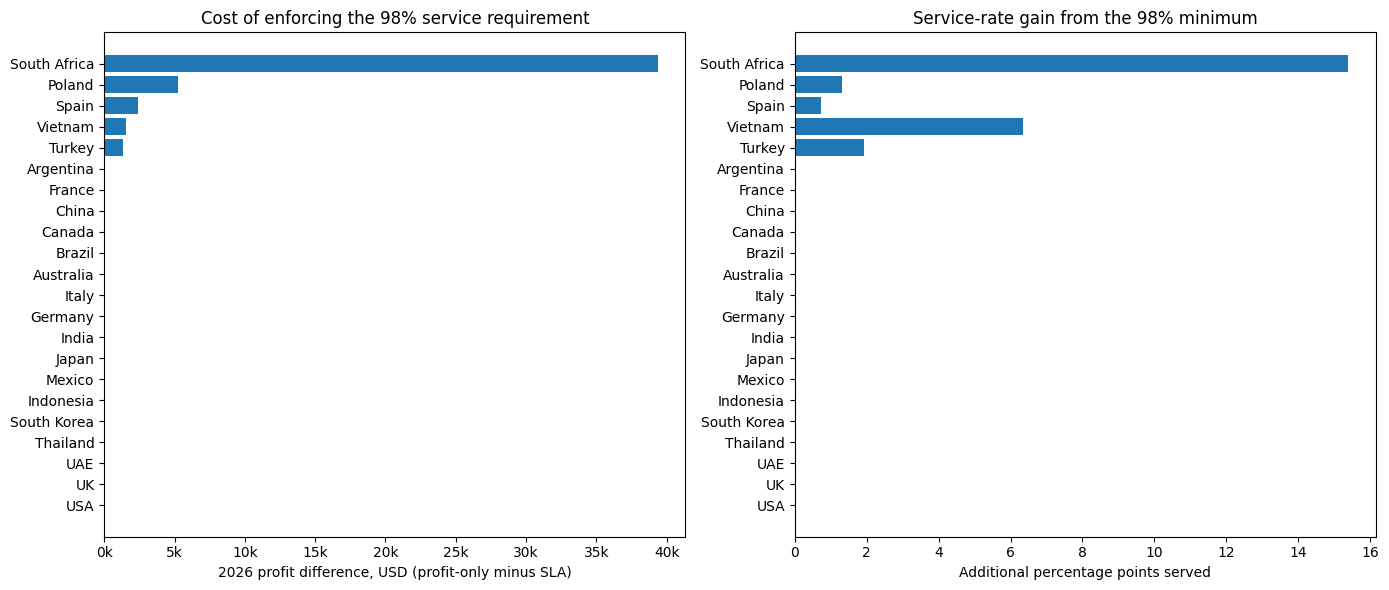

In [12]:
all_country_optimized = []
all_country_plans = []
all_country_solver_audits = []
if OPTIMIZE_ALL_COUNTRIES:
    for country in countries.Country:
        for label, min_rate in [('Profit only', None), ('Profit with SLA', MIN_ANNUAL_SERVICE_RATE)]:
            plan, detail, audit, meta = simulate_optimized_plan(country, min_rate)
            detail['Optimization_Mode'] = label
            all_country_plans.append(plan)
            all_country_optimized.append(detail)
            all_country_solver_audits.append({'Mode': label, **meta})
    all_country_detail = pd.concat(all_country_optimized, ignore_index=True)
    country_metrics = (all_country_detail
        .groupby(['Country', 'Optimization_Mode'], as_index=False)
        .agg(Profit_USD=('Modeled_Profit_USD', 'sum'),
             Revenue_USD=('Modeled_Revenue_USD', 'sum'),
             Staffing_Cost_USD=('Total_Staffing_Cost_USD', 'sum'),
             Arrivals=('Arrivals', 'sum'),
             Served=('Served', 'sum'),
             Hires=('Hires_Ordered', 'sum'),
             Releases=('Releases', 'sum')))
    country_metrics['Service_Rate_%'] = (100*country_metrics.Served/country_metrics.Arrivals).round(2)
    full_summary = (country_metrics.groupby('Optimization_Mode', as_index=False)
        .agg(Model_Profit_USD=('Profit_USD','sum'),
             Model_Revenue_USD=('Revenue_USD','sum'),
             Model_Cost_USD=('Staffing_Cost_USD','sum'),
             Arrivals=('Arrivals','sum'), Served=('Served','sum'), Hires=('Hires','sum')))
    full_summary['Aggregate_Service_Rate_%'] = (100*full_summary.Served/full_summary.Arrivals).round(3)
    print('All-country results: 22 country-specific optimized plans per objective (44 MILPs)')
    display(full_summary.round(2))
    print('Country-level results:')
    display(country_metrics[['Country','Optimization_Mode','Hires','Profit_USD','Service_Rate_%']]
            .sort_values(['Country','Optimization_Mode']).round(2))
else:
    print('Optional 22-country optimization OFF. Set OPTIMIZE_ALL_COUNTRIES=True in Section 6.')

if OPTIMIZE_ALL_COUNTRIES:
    # For a live classroom demo: reveal the profit/service trade-off by country.
    from matplotlib.ticker import FuncFormatter
    pivot = country_metrics.pivot(index='Country', columns='Optimization_Mode', values=['Profit_USD','Service_Rate_%'])
    country_order = (pivot['Profit_USD']['Profit only'] - pivot['Profit_USD']['Profit with SLA']).sort_values(ascending=False).index
    lost_profit = (pivot['Profit_USD']['Profit only'] - pivot['Profit_USD']['Profit with SLA']).loc[country_order]
    service_gain = (pivot['Service_Rate_%']['Profit with SLA'] - pivot['Service_Rate_%']['Profit only']).loc[country_order]
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    axes[0].barh(country_order[::-1], lost_profit.iloc[::-1])
    axes[0].set_title('Cost of enforcing the 98% service requirement')
    axes[0].set_xlabel('2026 profit difference, USD (profit-only minus SLA)')
    axes[0].xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x/1000:,.0f}k'))
    axes[1].barh(country_order[::-1], service_gain.iloc[::-1])
    axes[1].set_title('Service-rate gain from the 98% minimum')
    axes[1].set_xlabel('Additional percentage points served')
    plt.tight_layout()
    plt.show()


## 7 · Create an **actual LangChain decision-maker**

This is the direct equivalent of `GenAI_Order_Quantity()` in the Beer Game lab. `ChatPromptTemplate` serializes the current staffing state, including calculated capacity and hiring limits; `ChatOpenAI` produces a **new staffing decision every month**; `StrOutputParser` and Python validate it. The model is not asked to hallucinate final profit/cost numbers; the engine calculates those.

**Live model compatibility:** The sample uses `gpt-4.1-mini` and avoids `stop` or model-specific temperature settings. You can change the model to one enabled for your API key.

In [13]:
GENAI_SYSTEM_PROMPT = """You are the monthly staffing decision-maker in a Google advertiser onboarding SIMULATION.
You are playing the same role as the ordering agent in the Beer Game: you choose a NEW action EVERY MONTH.
Choose (A) the number of new flexible agents to order ('hire') and (B) the number of active flexible agents to release ('release').
Your financial objective is to MAXIMIZE TOTAL MODELED 2026 PROFIT, which is modeled recurring
revenue from served advertiser sign-ups MINUS ongoing agent salaries and one-time hiring fees.
Do not confuse 100% service with maximum profit: a marginal hire can be unprofitable within 2026.
Balance profit against the explicitly configured service objective if supplied.
The input is a JSON snapshot of facts available BEFORE current-month actual arrivals are revealed.
You may use recent_history, backlog_start, forecast_this_month, forecast_next_month, pending_hires and salary assumptions.
Hires activate ONLY after hire_lead_months; pending hires must not be double-counted.
IMPORTANT: The JSON includes ALREADY-CALCULATED capacities and maximum justified hires.
Never hire merely because flexible agents are zero, because a month is busy, or to be safe.
Existing agents provide onboarding capacity even if no flexible agents exist.
If max_justified_hires is ZERO, hire MUST be ZERO. If it is positive, hire at most that number.
If current capacity already exceeds next-month target, new hiring cannot increase the number of serviced signups.
Consider releasing surplus flexible agents, up to max_safe_releases, to avoid recurring salary costs.
An idle hired agent costs salary every month and has a hiring fee, even if it serves zero signups.
You MUST compare projected next-month demand with projected_next_month_capacity_before_new_hires.
No hires in the final month when they would activate after the horizon.
Never release more than the active_flexible_agents. Never suggest a negative or fractional number, or both hire and release together.
Never hire past the final simulated month, or above max_hires_per_month.
You may recommend holding staffing unchanged by choosing both zeros.
Make your own decision rather than requesting a user-supplied plan. Do NOT compute final realized financial results.
All revenue numbers are scenario assumptions, not actual Google figures.
If optimizer_reference is included, it is a mathematically generated FULL-FORECAST benchmark.
You may use it as advice but label its role honestly: following it is hybrid GenAI + optimization,
NOT an independent LLM discovery. If the benchmark recommends zero hires, do not add idle staff.
Respond with ONLY a JSON object: {"hire": integer, "release": integer, "reason": "short explanation"}.
"""

def parse_genai_decision(text):
    if not isinstance(text,str): raise ValueError('LLM reply was not text')
    # A model sometimes wraps otherwise valid JSON in markdown fences.
    cleaned=re.sub(r'^```(?:json)?\s*|\s*```$', '', text.strip(), flags=re.I).strip()
    response=json.loads(cleaned)
    return response

def make_genai_policy(model='gpt-4.1-mini'):
    from langchain_openai import ChatOpenAI
    from langchain_core.prompts import ChatPromptTemplate
    from langchain_core.output_parsers import StrOutputParser
    from langchain_core.messages import SystemMessage
    prompt = ChatPromptTemplate.from_messages([
        SystemMessage(content=GENAI_SYSTEM_PROMPT),
        ('human', 'Staffing game state for this month:\n{state_json}\nDecide hire and release for this month.')
    ])
    # This chain is invoked INSIDE simulate_game(), once per month.
    chain = prompt | ChatOpenAI(model=model, timeout=60, max_retries=1) | StrOutputParser()
    def decide(state):
        reply = chain.invoke({'state_json':json.dumps(state,sort_keys=True)})
        return parse_genai_decision(reply)
    return decide

print('LangChain agent definition ready. No paid model calls have been made.')

LangChain agent definition ready. No paid model calls have been made.


## 8 · Full GenAI vs. GenAI-Assisted (human review)

- **Full Gen-AI:** apply the model's *validated* decision automatically.
- **GenAI-Assisted:** show the model's recommendation and let the human accept or override **before** the simulator proceeds. This matches the Beer Game's approaches.

The model is called each month. The next prompt reflects prior hiring actions, pending staff, served cases, and backlog. This is **active AI decision-making**, not a static text parser or a one-off recommendation.
The human review screen shows the **model's raw suggestion**. The simulator then applies the same capacity guardrails to accepted, overridden, or fully autonomous actions and logs any adjustment.


In [14]:
def human_review_agent(ai_policy):
    def decide(state):
        proposed=check_action(ai_policy(state),state)
        print(f"\n{state['country']} month {state['month']} | AI suggests hire={proposed['hire']}, release={proposed['release']}")
        print('AI rationale:',proposed['reason'])
        raw=input('Press ENTER to accept, or enter HIRE,RELEASE to override: ').strip()
        if not raw: return {**proposed,'reason':'Human accepted: '+proposed['reason']}
        pieces=[int(x.strip()) for x in raw.split(',')]
        if len(pieces)!=2: raise ValueError('Override must be two integers, e.g. 5,0')
        return check_action({'hire':pieces[0],'release':pieces[1],
                             'reason':'Human override of AI suggestion'},state)
    return decide

# Example JSON and safety smoke tests; these do not contact an LLM.
assert parse_genai_decision('{"hire": 4, "release": 0, "reason": "Forecast growth"}')['hire']==4
assert check_action({'hire':4,'release':0}, {'month':3,'active_flexible_agents':0})['hire']==4
print('LangChain parser and action validation ready.')

LangChain parser and action validation ready.


## 9 · Profit-guided LangChain decision-making

Want GenAI itself to **use** the optimizer rather than merely race against it? The `OPTIMIZER_GUIDANCE_FOR_GENAI` switch supplies the solver's **forecast-wide recommended monthly action** to LangChain's state. The AI still decides each month, but the result is a **hybrid optimizer + GenAI strategy**, not independent GenAI skill.

If a model recommendation violates a safety constraint or available capacity, the simulator still logs both the **raw** and **applied** actions. The simulation never trusts the LLM to compute financial results. This mode still requires your OpenAI API key.


In [15]:
# Switch the hybrid on only if you explicitly want optimizer recommendations in the LLM prompt.
OPTIMIZER_GUIDANCE_FOR_GENAI = True
OPTIMIZER_REFERENCE_MODE = 'Profit with SLA'  # or 'Profit only'


def attach_optimizer_guidance(genai_policy, plan):
    by_month = {int(r.Month): r for r in plan.itertuples(index=False)}
    def decide(state):
        month = state['month']
        recommendation = by_month[month]
        augmented = dict(state)
        augmented['optimizer_reference'] = {
            'monthly_hires': int(recommendation.New_Hires),
            'monthly_releases': int(recommendation.Releases),
            'forecast_wide_strategy': plan.Mode.iloc[0],
            'note': 'This is forecast-wide solver advice, not independent GenAI reasoning.'
        }
        return genai_policy(augmented)
    return decide


## 10 · **PLAY THE GAME using real GenAI** (explicit opt-in)

**This is the cell to run if you want GenAI to decide the staffing.** Set `RUN_LIVE_GENAI=True` after adding `OPENAI_API_KEY`. A one-country demonstration makes **up to 12 LLM decisions** (one per month), not 264 calls across all countries. `RUN_GENAI_ASSISTED=True` also requires your input every month.

In Colab: add your API key under Secrets with the name `OPENAI_API_KEY`, or set it through your notebook's secure environment. Do not paste keys into the notebook or CSV exports.

If you run with the flag off, it explicitly says **no real GenAI outcome exists**, rather than displaying a mock result labeled as GenAI.

In [16]:
RUN_LIVE_GENAI = True       # <-- Set True to actually use OpenAI through LangChain.
RUN_GENAI_ASSISTED = False   # <-- Set True only if you want human approval 12 times.
MODEL_NAME = 'gpt-4.1-mini'  # Or another model available in your account.

def load_colab_secret_if_present():
    if os.environ.get('OPENAI_API_KEY'): return True
    try:
        from google.colab import userdata
        key=userdata.get('OPENAI_API_KEY')
        if key:
            os.environ['OPENAI_API_KEY']=key
            return True
    except Exception:
        pass
    return False

live_result = None
live_audit = None
if RUN_LIVE_GENAI:
    if not load_colab_secret_if_present():
        raise RuntimeError('Set OPENAI_API_KEY in environment or Colab Secrets before enabling live mode.')
    ai_policy=make_genai_policy(MODEL_NAME)

    if OPTIMIZER_GUIDANCE_FOR_GENAI:
        ai_policy = attach_optimizer_guidance(ai_policy, optimizer_plans[OPTIMIZER_REFERENCE_MODE])
    label = ('GenAI + Profit Optimizer (LIVE)' if OPTIMIZER_GUIDANCE_FOR_GENAI
             else ('GenAI-Assisted (LIVE)' if RUN_GENAI_ASSISTED else 'Full GenAI (LIVE)'))
    decider=human_review_agent(ai_policy) if RUN_GENAI_ASSISTED else ai_policy
    live_result, live_audit=simulate_game(DEMO_COUNTRY,decider,label)
    print('LIVE LangChain decision loop completed.')
    display(live_result[['Month','Forecast','Proposed_Hires','Hires_Ordered','Proposed_Releases','Releases','Action_Source','Guardrail_Note','Served','Backlog_End','Modeled_Profit_USD']])
    if (live_result.Action_Source=='SAFE_FALLBACK_NOT_LLM').any():
        print('WARNING: Some months used SAFE FALLBACK; inspect their audit entries.')
else:
    print('OFFLINE MODE: no LLM has been called. To play with real GenAI set RUN_LIVE_GENAI=True.')

LIVE LangChain decision loop completed.


,Month,Forecast,Proposed_Hires,Hires_Ordered,Proposed_Releases,Releases,Action_Source,Guardrail_Note,Served,Backlog_End,Modeled_Profit_USD
0,1,1025.0,0,0,0,0,GenAI + Profit Optimizer (LIVE),,1025,0,-1.104211e+05
1,2,988.4,0,0,0,0,GenAI + Profit Optimizer (LIVE),,988,0,5.972251e+05
2,3,1000.9,0,0,0,0,GenAI + Profit Optimizer (LIVE),,1001,0,1.314182e+06
3,4,995.1,0,0,0,0,GenAI + Profit Optimizer (LIVE),,995,0,2.026842e+06
4,5,989.2,0,0,0,0,GenAI + Profit Optimizer (LIVE),,989,0,2.735205e+06
5,6,848.3,0,0,0,0,GenAI + Profit Optimizer (LIVE),,848,0,3.342577e+06
6,7,922.0,0,0,0,0,GenAI + Profit Optimizer (LIVE),,922,0,4.002951e+06
7,8,888.1,0,0,0,0,GenAI + Profit Optimizer (LIVE),,888,0,4.638974e+06
8,9,1079.9,17,17,0,0,GenAI + Profit Optimizer (LIVE),,1080,0,5.412514e+06
9,10,1469.3,1,1,0,0,GenAI + Profit Optimizer (LIVE),,1469,0,6.248867e+06


## 11 · Compare the same demand under different decision approaches

The results here have meaning only when you know which approaches actually ran. A live LLM row only appears if Step 8 completed; the offline controls are not reported as an AI experiment.
**This chart compares policies for the chosen `DEMO_COUNTRY` only.** Aggregate 22-country optimization appears in Section 6b; one-country live GenAI is not a 22-country AI result.


,Policy,Arrivals,Served,Abandoned,Year_End_Backlog,Hires_Ordered,Modeled_Revenue_USD,Staffing_Cost_USD,Modeled_Profit_USD,Service_Rate
0,Average rule,13057,13057,0,0,36,56350983.47,10701922.63,45649060.84,100.00
1,GenAI + Profit Optimizer (LIVE),13057,13057,0,0,18,56594505.44,10590004.39,46004501.05,100.00
2,Keep current staff,13057,12648,0,409,0,55936279.89,10134818.40,45801461.49,96.87
3,Manual,13057,12648,0,409,0,55936279.89,10134818.40,45801461.49,96.87
4,Profit max (98% service minimum),13057,13053,0,4,18,56591640.48,10512283.39,46079357.09,99.97
5,Profit max (no service minimum),13057,13053,0,4,18,56591640.48,10512283.39,46079357.09,99.97


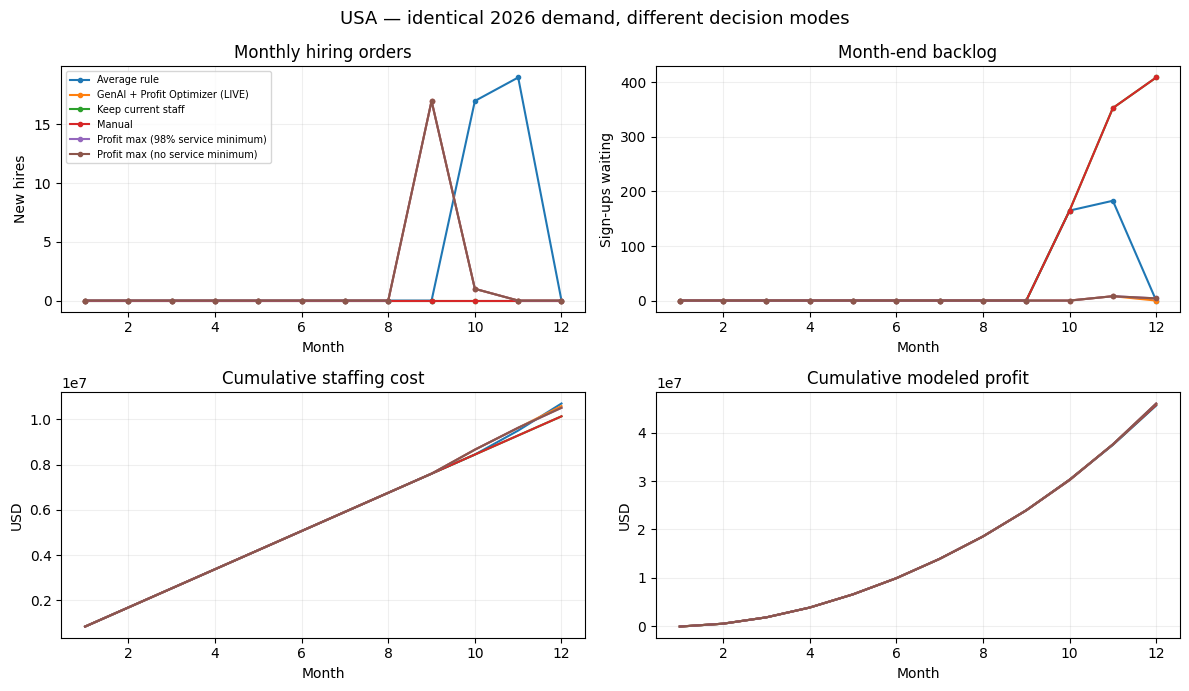

In [17]:
combined=[control_results, pd.concat(optimizer_runs.values(), ignore_index=True)]
if live_result is not None: combined.append(live_result)
all_results=pd.concat(combined,ignore_index=True)
summary=summarize_runs(all_results)
display(summary.round(2))
fig,axes=plt.subplots(2,2,figsize=(12,7))
for name, part in all_results.groupby('Policy'):
    part=part.sort_values('Month')
    axes[0,0].plot(part.Month,part.Hires_Ordered,marker='.',label=name)
    axes[0,1].plot(part.Month,part.Backlog_End,marker='.',label=name)
    axes[1,0].plot(part.Month,part.Total_Staffing_Cost_USD.cumsum(),label=name)
    axes[1,1].plot(part.Month,part.Modeled_Profit_USD.cumsum(),label=name)
for ax,title,ylab in zip(axes.flat,['Monthly hiring orders','Month-end backlog','Cumulative staffing cost','Cumulative modeled profit'],
                          ['New hires','Sign-ups waiting','USD','USD']):
    ax.set_title(title); ax.set_xlabel('Month');ax.set_ylabel(ylab);ax.grid(alpha=.2)
axes[0,0].legend(fontsize=7, loc='upper left')
plt.suptitle(f'{DEMO_COUNTRY} — identical 2026 demand, different decision modes',fontsize=13)
plt.tight_layout();plt.show()

## 12 · Export simulation and decision audit

Every output record contains the **action, decision source, prompt-visible state, and calculated results**. This supports reproducibility and makes it easy to see whether a month was decided by a real LLM or by the safe fallback.



In [18]:
out_dir=Path('outputs/step03_beergame_genai');out_dir.mkdir(parents=True,exist_ok=True)
all_results.to_csv(out_dir/'monthly_results.csv',index=False)
summary.to_csv(out_dir/'policy_comparison.csv',index=False)
audits=list(control_audits.values()) + list(optimizer_audits.values())
if live_audit is not None: audits.append(live_audit)
pd.concat(audits,ignore_index=True).to_csv(out_dir/'decision_audit.csv',index=False)
print('Saved:', *(str(p) for p in sorted(out_dir.glob('*.csv'))),sep='\n - ')
print('Important: monthly_results includes LIVE GenAI ONLY if enabled and executed in Section 10.')
pd.concat(optimizer_plans.values(), ignore_index=True).to_csv(out_dir/'profit_maximizing_staffing_plan.csv',index=False)
pd.DataFrame(optimizer_metadata).to_csv(out_dir/'optimization_solver_audit.csv', index=False)
if all_country_plans:
    pd.concat(all_country_plans,ignore_index=True).to_csv(out_dir/'all_22_countries_optimized_plans.csv',index=False)
print('Also saved profit_maximizing_staffing_plan.csv and optimization_solver_audit.csv')

if all_country_plans:
    country_metrics.to_csv(out_dir/'country_profit_service_comparison.csv', index=False)
    full_summary.to_csv(out_dir/'all_country_profit_summary.csv', index=False)
    pd.DataFrame(all_country_solver_audits).to_csv(out_dir/'all_country_optimizer_audit.csv', index=False)
    print('All-country profit/service analysis CSVs exported.')


Saved:
 - outputs/step03_beergame_genai/decision_audit.csv
 - outputs/step03_beergame_genai/monthly_results.csv
 - outputs/step03_beergame_genai/policy_comparison.csv
Important: monthly_results includes LIVE GenAI ONLY if enabled and executed in Section 10.
Also saved profit_maximizing_staffing_plan.csv and optimization_solver_audit.csv
All-country profit/service analysis CSVs exported.


## 13 · How to interpret / present the findings

1. **Step 3** is a replayable, deterministic simulator: monthly hiring and release decisions -> capacity, served sign-ups, backlog, monthly salaries, hire fees, modeled revenue, and profit. Full GenAI uses LangChain to choose an action at each monthly turn, just like the Beer Game.
2. Profit maximization: an integer-programming solver searches annual staffing plans and evaluates them using exactly the Step 3 engine. The two optimizer modes reveal the tradeoff between modeled profit and an explicit service-level target.
3. **Comparisons:** Report full-model GenAI, rule-based controls, **profit maximizing** (no service floor), and **profit maximizing with service floor**. A live GenAI experiment only exists if Section 10 really ran with an API key.
4. **Critical assumptions:** 10 cases/agent/month, 20% existing-agent allocation, 1-month hire lead, 2-month maximum waiting window, 8% hire fee, 10% advertiser budget capture, and 98% annual service floor are *classroom inputs*, not actual Google policies.
5. **Important modeling limits:** Existing staff payroll is a fixed allocated cost; a lower modeled profit may still be preferable if you value service, LTV, or retention beyond December 2026. The optimizer knows all 12 monthly forecasts, unlike the live GenAI agent. The yearly revenue model does not calculate future-year economics. A positive solver optimality gap indicates best-found, not proven global optimum.
6. **Output files** under `outputs/step03_beergame_genai/`: `monthly_results.csv`, `policy_comparison.csv`, `profit_maximizing_staffing_plan.csv`, `optimization_solver_audit.csv`, `decision_audit.csv` and optional `all_22_countries_optimized_plans.csv`.

**For presentation:** A model choosing zero hires can be correct under profit maximization if current capacity is ample. Profit optimization is not the same as hiring aggressively or guaranteeing all demand is served.
